In [1]:
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def find_project_root(start: Path | None = None) -> Path:
    start = Path.cwd() if start is None else Path(start).resolve()
    for path in [start, *start.parents]:
        if (path / "codes").is_dir() and (path / "gfn2-xtb.toml").exists():
            return path
    raise RuntimeError("Could not find project root. Run this notebook inside optxTB-MD or set PROJECT_ROOT_PATH manually.")


PROJECT_ROOT_PATH = find_project_root()
print("PROJECT_ROOT_PATH:", PROJECT_ROOT_PATH)

PROJECT_ROOT_PATH: /dss/dsshome1/09/ge45fol2/cluster_vs_pbc/optxTB-MD


In [2]:
def generate_parameter_info(param_changes, variation=0.30, kernel_abs=0.03, near_one_width=0.20, positivity_eps=1e-12, fallback_zero_abs=0.20, fixed_components=None):
    if fixed_components is None:
        fixed_components = set()

    def _percent_box(val):
        if val == 0:
            return [-fallback_zero_abs, +fallback_zero_abs]
        lo = min(val * (1 - variation), val * (1 + variation))
        hi = max(val * (1 - variation), val * (1 + variation))
        return [lo, hi]

    def _near_one_box():
        return [max(positivity_eps, 1.0 - near_one_width), 1.0 + near_one_width]

    def _make_bound(elem, key, val, idx=None):
        if key == "dkernel" and elem == "Na":
            lo, hi = -abs(kernel_abs), abs(kernel_abs)
        elif key in {"Na-O", "Na-H", "Cl-H", "Cl-O", "H-H", "O-O", "O-H"}:
            lo, hi = _near_one_box()
        elif key == "gam":
            lo, hi = _percent_box(val)
            lo = max(lo, positivity_eps)
        else:
            lo, hi = _percent_box(val)

        if not (hi > lo):
            mid = 0.5 * (lo + hi)
            tiny = max(1e-9, abs(mid) * 1e-12)
            lo, hi = mid - tiny, mid + tiny
        return [lo, hi]

    names = []
    bounds = []
    vector = []
    structure = {}
    for elem, params in param_changes.items():
        structure[elem] = {}
        for key, value in params.items():
            if isinstance(value, list):
                structure[elem][key] = []
                for i, val in enumerate(value):
                    if key == "lgam" and i == 0:
                        structure[elem][key].append("Fixing to 1.0")
                        continue
                    if (elem, key, i) in fixed_components:
                        structure[elem][key].append(("__fixed__", val))
                        continue
                    par_name = f"{elem}_{key}_{i}"
                    names.append(par_name)
                    bounds.append(_make_bound(elem, key, val, idx=i))
                    vector.append(val)
                    structure[elem][key].append(par_name)
            else:
                par_name = f"{elem}_{key}"
                names.append(par_name)
                bounds.append(_make_bound(elem, key, value))
                vector.append(value)
                structure[elem][key] = par_name
    return names, bounds, vector, structure


def load_pareto_point(run_dir, index):
    results_path = sorted((PROJECT_ROOT_PATH / run_dir).glob("*_results_*.npz"))[0]
    with np.load(results_path) as data:
        return data["X_pareto"][index]


def deviation_table(names, default, selected):
    selected_df = pd.DataFrame({"name": names, "default": default})
    for label, (run_dir, index, rho, rho_err) in selected.items():
        selected_df[label] = load_pareto_point(run_dir, index)
    for label in selected:
        selected_df[f"delta_percent {label}"] = (selected_df[label] - selected_df["default"]) / selected_df["default"] * 100.0
    return selected_df


def plot_deviations(selected_df, selected):
    fig, ax = plt.subplots(figsize=(9, 4.5))
    x = np.arange(len(selected_df["name"]))
    width = 0.8 / len(selected)
    for k, (label, (run_dir, index, rho, rho_err)) in enumerate(selected.items()):
        offset = (k - (len(selected) - 1) / 2) * width
        ax.bar(x + offset, selected_df[f"delta_percent {label}"], width, label=rf"{label}: $\rho$ = {rho} ± {rho_err} g/cm$^3$")
    ax.axhline(0, linewidth=1)
    ax.set_xticks(x)
    ax.set_xticklabels(selected_df["name"], rotation=0)
    ax.set_ylabel("Change vs default (%)")
    ax.set_title("Selected Pareto vectors: parameter changes")
    ax.grid(True, axis="y", alpha=0.3)
    ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

In [3]:
water_param_changes = {
    "kpair": {
        "O-O": 1.0,
        "O-H": 1.0,
    },
    "H": {
        "zeff": 1.1053880000000000,
        "arep": 2.2137169999999999,
    },
    "O": {
        "zeff": 5.7844150000000001,
        "arep": 2.1657120000000001,
    },
}

water_names, _, water_default, _ = generate_parameter_info(water_param_changes)
water_default = np.asarray(water_default, dtype=float)

water_selected = {
    r"PBC (E,F,$\Xi$) 3": ("optimization/T_pbc/hpc_runs/nsga3_pbc_efxi_loss_210083_20260529_092923", 3, 1.023, 0.048),
    r"PBC (E,F) 30": ("optimization/T_pbc/hpc_runs/nsga3_pbc_efxi_loss_215185_20260702_084458", 30, 1.0732, 0.0402),
    r"Cluster (E,F) 249": ("optimization/T1_partial_charge_schemes/hpc_runs/nsga_t1_ef_water_215904_20260720_101414", 249, 1.097, 0.039),
}

water_df = deviation_table(water_names, water_default, water_selected)
water_df

,name,default,"PBC (E,F,$\Xi$) 3","PBC (E,F) 30","Cluster (E,F) 249","delta_percent PBC (E,F,$\Xi$) 3","delta_percent PBC (E,F) 30","delta_percent Cluster (E,F) 249"
0,kpair_O-O,1.000000,1.090439,1.052772,1.053113,9.043854,5.277195,5.311312
1,kpair_O-H,1.000000,1.029229,1.018841,1.014758,2.922870,1.884102,1.475757
2,H_zeff,1.105388,1.149101,1.277170,1.094559,3.954555,15.540387,-0.979661
3,H_arep,2.213717,2.662444,2.580476,2.530020,20.270287,16.567543,14.288332
4,O_zeff,5.784415,5.564424,6.901537,6.928028,-3.803168,19.312623,19.770587
5,O_arep,2.165712,1.707798,2.070842,1.994129,-21.143822,-4.380551,-7.922702


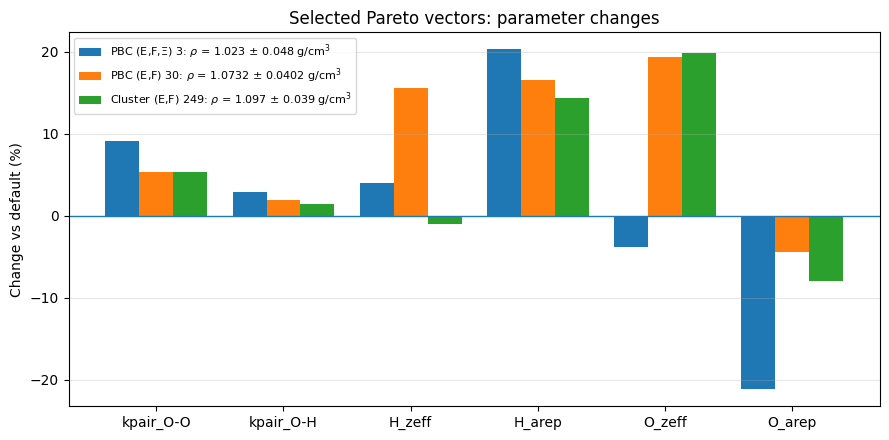

In [4]:
plot_deviations(water_df, water_selected)

In [5]:
na_param_changes = {
    "kpair": {
        "Na-O": 1.0,
        "Na-H": 1.0,
    },
    "Na": {
        "slater": [0.7637870000000000, 0.5735530000000000],
        "gam": 0.2710560000000000,
        "zeff": 5.2449170000000001,
        "arep": 0.5727280000000000,
    },
}

na_names, _, na_default, _ = generate_parameter_info(na_param_changes, fixed_components={("Na", "slater", 1)})
na_default = np.asarray(na_default, dtype=float)

na_selected = {
    r"PBC (E,F,$\Xi$) 3": ("optimization/T_pbc/hpc_runs/nsga3_pbc_na_215845_20260719_031739", 3, 1.075, 0.05),
    r"Cluster (E,F,IH) 249/89": ("optimization/T_all_partial_charge_schemes/hpc_runs/nsga3_t2na_t3_efq_na_reg_216898_20260806_174242", 89, 1.164, 0.042),
    r"Cluster (E,F,CM5) 249/2": ("optimization/T_all_partial_charge_schemes/hpc_runs/nsga3_t2na_t3_efq_na_reg_216899_20260809_183219", 2, 1.15, 0.041),
}

na_df = deviation_table(na_names, na_default, na_selected)
na_df

,name,default,"PBC (E,F,$\Xi$) 3","Cluster (E,F,IH) 249/89","Cluster (E,F,CM5) 249/2","delta_percent PBC (E,F,$\Xi$) 3","delta_percent Cluster (E,F,IH) 249/89","delta_percent Cluster (E,F,CM5) 249/2"
0,kpair_Na-O,1.000000,0.978497,1.034631,1.006653,-2.150348,3.463148,0.665333
1,kpair_Na-H,1.000000,0.903832,0.988889,1.062074,-9.616764,-1.111070,6.207365
2,Na_slater_0,0.763787,0.754752,0.778555,0.852035,-1.182913,1.933475,11.554046
3,Na_gam,0.271056,0.310419,0.264198,0.295577,14.522065,-2.529961,9.046609
4,Na_zeff,5.244917,5.490369,5.438213,5.486403,4.679804,3.685406,4.604186
5,Na_arep,0.572728,0.477404,0.425662,0.515271,-16.643852,-25.678125,-10.032116


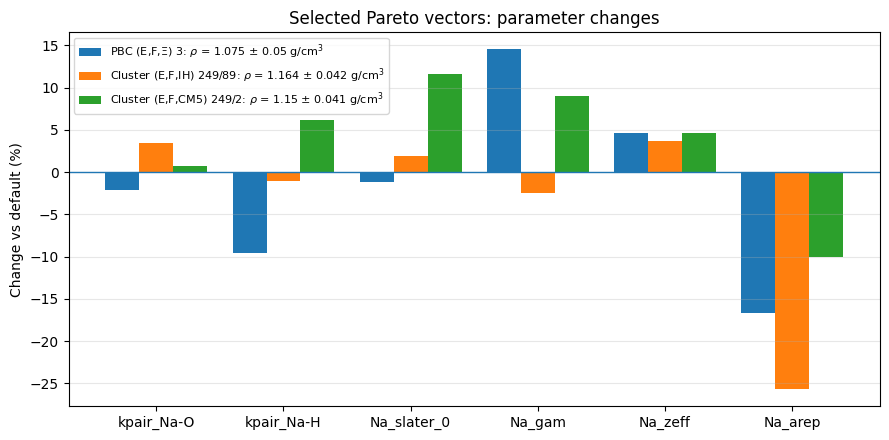

In [6]:
plot_deviations(na_df, na_selected)